Phase 3: Multivariate Analysis & Clustering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
# 1. Create/Load sample customer data (Annual Income vs. Spending Score)
# In real life, this would come from a CSV or database export.
np.random.seed(42)
income = np.random.normal(50, 15, 200) # Income in $k
spending = np.random.normal(50, 20, 200) # Spending score (1-100)
df_cust = pd.DataFrame({'Annual_Income': income, 'Spending_Score': spending})

In [3]:
df_cust.head()

,Annual_Income,Spending_Score
0,57.450712,57.155747
1,47.926035,61.215691
2,59.715328,71.661025
3,72.845448,71.076041
4,46.487699,22.446613


In [8]:
# 2. Multivariate Scaling (Crucial for distance-based algorithms!)
# Multivariate analysis requires all features to be on the same scale so one doesn't overpower the other.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_cust)

# 3. Apply K-Means Clustering (Multivariate grouping)
# We want to group customers into 4 distinct segments
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cust['Cluster'] = kmeans.fit_predict(scaled_features)

C:\Users\nurul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


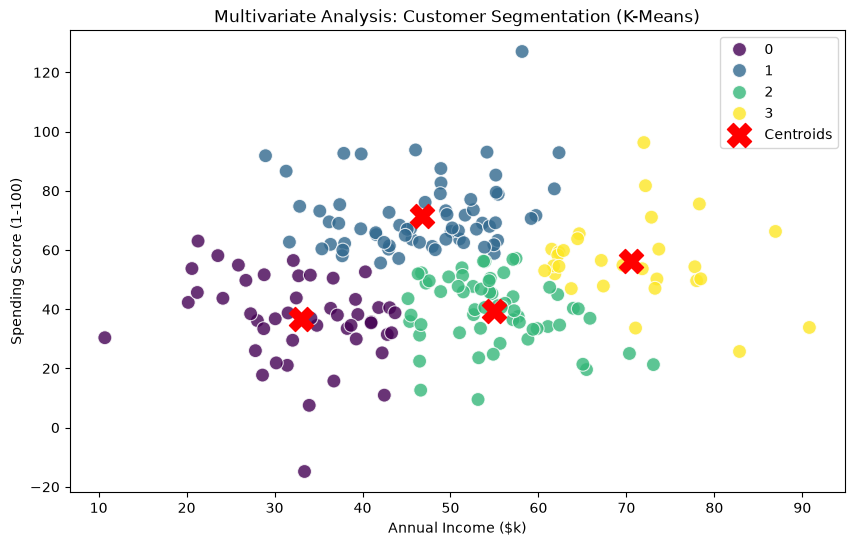

In [9]:
# 4. Visualize the multi-dimensional clusters in 2D space
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual_Income', 
    y='Spending_Score', 
    hue='Cluster', 
    data=df_cust, 
    palette='viridis', 
    s=100, 
    alpha=0.8
)

# Plot the cluster centers (centroids)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    s=300, 
    c='red', 
    marker='X', 
    label='Centroids'
)

plt.title('Multivariate Analysis: Customer Segmentation (K-Means)')
plt.xlabel('Annual Income ($k)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

The plot shows of 4 groups. The purple shows low-income where they spend not more than 70 passing score. The blue shows middle-income where their minimum spending score is above 40. This shows that the customers love to spend despite their annual income. Green customers are moderate in terms of spending with their annual income. The yellow shows that they are the high-tier customers who actively spend from moderate to high.